# Отчёт о качестве данных — Лабораторная работа № 5 (Вариант 2)

**Студент:** Мурашова Арина  ПМИ-3
**Источник:** `books.toscrape.com` (обход по 50 категориям)  

Ноутбук читает фактические артефакты прогонов из `../data/` и `../jobstate/` (без фиктивных значений).

In [13]:
import json
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..').resolve()
DATA_DIR = ROOT / 'data'
DB_PATH = DATA_DIR / 'crawl.db'
STATS_FINAL = DATA_DIR / 'stats_final.json'

assert DB_PATH.exists(), f'Сначала запустите паука (не найдена БД {DB_PATH})'
assert STATS_FINAL.exists(), f'Не найден файл статистики {STATS_FINAL}'

conn = sqlite3.connect(DB_PATH)
df = pd.read_sql_query('SELECT * FROM books', conn)
conn.close()

stats = json.loads(STATS_FINAL.read_text(encoding='utf-8'))
print(f'Всего записей в БД : {len(df)}')
print(f'Уникальных UPC     : {df["upc"].nunique()}')
print(f'Уникальных категорий (из меню): {df["category_from_menu"].nunique()}')
display(df.head(5))

Всего записей в БД : 358
Уникальных UPC     : 358
Уникальных категорий (из меню): 36


,upc,title,price,price_excl_tax,price_incl_tax,tax,stock,rating,reviews,category,category_from_menu,description,url,list_page,scraped_at
0,abeafe151a587d3b,The Long Shadow of Small Ghosts: Murder and Me...,10.97,10.97,10.97,0.0,15,1,0,Crime,Crime,In Cold Blood meets Adrian Nicole LeBlanc’s Ra...,https://books.toscrape.com/catalogue/the-long-...,https://books.toscrape.com/catalogue/category/...,2026-11-19T10:58:39+00:00
1,88c21fcd38e2486e,Dark Notes,19.19,19.19,19.19,0.0,15,5,0,Erotica,Erotica,They call me a slut. Maybe I am.Sometimes I do...,https://books.toscrape.com/catalogue/dark-note...,https://books.toscrape.com/catalogue/category/...,2026-11-19T10:58:39+00:00
2,bb8245f52c7cce8f,Amid the Chaos,36.58,36.58,36.58,0.0,15,1,0,Cultural,Cultural,Some people call Eritrea the “North Korea of A...,https://books.toscrape.com/catalogue/amid-the-...,https://books.toscrape.com/catalogue/category/...,2026-11-19T10:58:39+00:00
3,3968e3fbf4695d7c,Equal Is Unfair: America's Misguided Fight Aga...,56.86,56.86,56.86,0.0,12,1,0,Politics,Politics,We’ve all heard that the American Dream is van...,https://books.toscrape.com/catalogue/equal-is-...,https://books.toscrape.com/catalogue/category/...,2026-11-19T10:58:40+00:00
4,f9c87ccb2bc4853b,The Art and Science of Low Carbohydrate Living,52.98,52.98,52.98,0.0,9,5,0,Health,Health,The Art And Science Of Low Carbohydrate Living...,https://books.toscrape.com/catalogue/the-art-a...,https://books.toscrape.com/catalogue/category/...,2026-11-19T10:58:40+00:00


## 1. Полнота полей (%) и проверка совпадения категорий (уровень 1 vs уровень 2)

In [14]:
completeness = pd.DataFrame({
    'не_пустых': df.apply(lambda s: s.notna() & (s.astype(str).str.strip() != '')).sum(),
    'всего': len(df),
})
completeness['полнота_%'] = (completeness['не_пустых'] / completeness['всего'] * 100).round(2)
display(completeness)

mismatch = (df['category'] != df['category_from_menu']).sum()
print(f'Расхождений category (карточка) vs category_from_menu (уровень 1): {mismatch}')

,не_пустых,всего,полнота_%
upc,358,358,100.0
title,358,358,100.0
price,358,358,100.0
price_excl_tax,358,358,100.0
price_incl_tax,358,358,100.0
tax,358,358,100.0
stock,358,358,100.0
rating,358,358,100.0
reviews,358,358,100.0
category,358,358,100.0


Расхождений category (карточка) vs category_from_menu (уровень 1): 0


## 2. Статистика итогового прогона (коды ответа, отбросы, трафик, время)

In [15]:
key_metrics = [
    'downloader/request_count',
    'downloader/response_count',
    'crawl/categories_discovered',
    'crawl/list_pages_visited',
    'item_scraped_count',
    'item_dropped_count',
    'db/rows_written',
    'retry/count',
    'downloader/response_bytes',
    'elapsed_time_seconds',
    'close_reason',
]
rows = [{'метрика': k, 'значение': stats.get(k, 0)} for k in key_metrics]
for k, v in sorted(stats.items()):
    if k.startswith(('downloader/response_status_count/', 'dropped/', 'errback/')):
        rows.append({'метрика': k, 'значение': v})

stats_df = pd.DataFrame(rows)
display(stats_df)

resp_mb = stats.get('downloader/response_bytes', 0) / (1024 * 1024)
elapsed = float(stats.get('elapsed_time_seconds', 0) or 0)
scraped = int(stats.get('item_scraped_count', 0) or 0)
print(f'Объём трафика   : {resp_mb:.2f} МБ')
print(f'Длительность    : {elapsed:.2f} с')
if elapsed > 0:
    print(f'Скорость        : {scraped / elapsed * 60:.1f} записей/мин')

,метрика,значение
0,downloader/request_count,404
1,downloader/response_count,404
2,crawl/categories_discovered,50
3,crawl/list_pages_visited,44
4,item_scraped_count,358
5,item_dropped_count,0
6,db/rows_written,358
7,retry/count,0
8,downloader/response_bytes,1589465
9,elapsed_time_seconds,126.82


Объём трафика   : 1.52 МБ
Длительность    : 126.82 с
Скорость        : 169.4 записей/мин


## 3. Демонстрация HTTPCACHE и JOBDIR (п. 4.5)

In [16]:
def load_if_exists(name):
    p = DATA_DIR / name
    return json.loads(p.read_text(encoding='utf-8')) if p.exists() else None

c1, c2 = load_if_exists('stats_cache_1.json'), load_if_exists('stats_cache_2.json')
if c1 and c2:
    cache_df = pd.DataFrame([
        {'прогон': 'HTTPCACHE прогон 1 (холодный)',
         'elapsed_s': round(float(c1.get('elapsed_time_seconds', 0)), 2),
         'requests': c1.get('downloader/request_count', 0),
         'httpcache/store': c1.get('httpcache/store', 0),
         'httpcache/hit': c1.get('httpcache/hit', 0)},
        {'прогон': 'HTTPCACHE прогон 2 (из кэша)',
         'elapsed_s': round(float(c2.get('elapsed_time_seconds', 0)), 2),
         'requests': c2.get('downloader/request_count', 0),
         'httpcache/store': c2.get('httpcache/store', 0),
         'httpcache/hit': c2.get('httpcache/hit', 0)},
    ])
    display(cache_df)

j1, j2 = load_if_exists('stats_job_1.json'), load_if_exists('stats_job_2.json')
if j1 and j2:
    job_df = pd.DataFrame([
        {'прогон': 'JOBDIR прогон 1 (прерван по лимиту)',
         'items': j1.get('item_scraped_count', 0),
         'dupefilter/filtered': j1.get('dupefilter/filtered', 0),
         'elapsed_s': round(float(j1.get('elapsed_time_seconds', 0)), 2)},
        {'прогон': 'JOBDIR прогон 2 (возобновление)',
         'items': j2.get('item_scraped_count', 0),
         'dupefilter/filtered': j2.get('dupefilter/filtered', 0),
         'elapsed_s': round(float(j2.get('elapsed_time_seconds', 0)), 2)},
    ])
    display(job_df)

job_dir = ROOT / 'jobstate'
if job_dir.exists():
    print('Содержимое jobstate/:', sorted(p.name for p in job_dir.iterdir() if p.name != '.gitkeep'))

,прогон,elapsed_s,requests,httpcache/store,httpcache/hit
0,HTTPCACHE прогон 1 (холодный),23.85,68,68,0
1,HTTPCACHE прогон 2 (из кэша),13.49,75,33,42


,прогон,items,dupefilter/filtered,elapsed_s
0,JOBDIR прогон 1 (прерван по лимиту),48,0,21.87
1,JOBDIR прогон 2 (возобновление),48,0,19.60


Содержимое jobstate/: ['requests.queue', 'requests.seen', 'spider.state']


## 4. Аналитические агрегаты и визуализация

In [17]:
# Агрегат 1: топ-10 категорий по числу книг, средней цене без налога и остаткам
cat_agg = (
    df.groupby('category_from_menu', as_index=False)
      .agg(
          книг=('upc', 'count'),
          средняя_цена=('price_excl_tax', 'mean'),
          средний_рейтинг=('rating', 'mean'),
          суммарный_остаток=('stock', 'sum'),
      )
      .sort_values('книг', ascending=False)
)
cat_agg['средняя_цена'] = cat_agg['средняя_цена'].round(2)
cat_agg['средний_рейтинг'] = cat_agg['средний_рейтинг'].round(2)
display(cat_agg.head(10))

# Агрегат 2: распределение рейтингов
rating_agg = df.groupby('rating', as_index=False).agg(
    книг=('upc', 'count'),
    средняя_цена=('price_excl_tax', 'mean'),
)
rating_agg['средняя_цена'] = rating_agg['средняя_цена'].round(2)
display(rating_agg)

# Агрегат 3: сводка по ценам и остаткам
display(df[['price_excl_tax', 'stock', 'rating', 'reviews']].describe().round(2))

,category_from_menu,книг,средняя_цена,средний_рейтинг,суммарный_остаток
1,Add a comment,67,35.80,2.76,516
13,Fantasy,48,39.59,3.08,372
35,Young Adult,45,36.15,3.31,317
14,Food and Drink,30,31.41,2.90,319
17,History,18,37.29,2.94,181
18,Horror,17,35.95,2.71,136
28,Science Fiction,16,33.80,2.25,125
6,Business,12,32.46,2.92,133
34,Thriller,11,31.43,2.73,119
19,Humor,10,33.50,3.40,84


,rating,книг,средняя_цена
0,1,85,34.94
1,2,70,37.37
2,3,64,34.95
3,4,64,37.32
4,5,75,36.13


,price_excl_tax,stock,rating,reviews
count,358.00,358.00,358.00,358.0
mean,36.09,8.48,2.93,0.0
std,14.53,5.39,1.47,0.0
min,10.00,1.00,1.00,0.0
25%,23.92,3.00,2.00,0.0
50%,37.26,7.00,3.00,0.0
75%,48.64,14.00,4.00,0.0
max,59.95,20.00,5.00,0.0


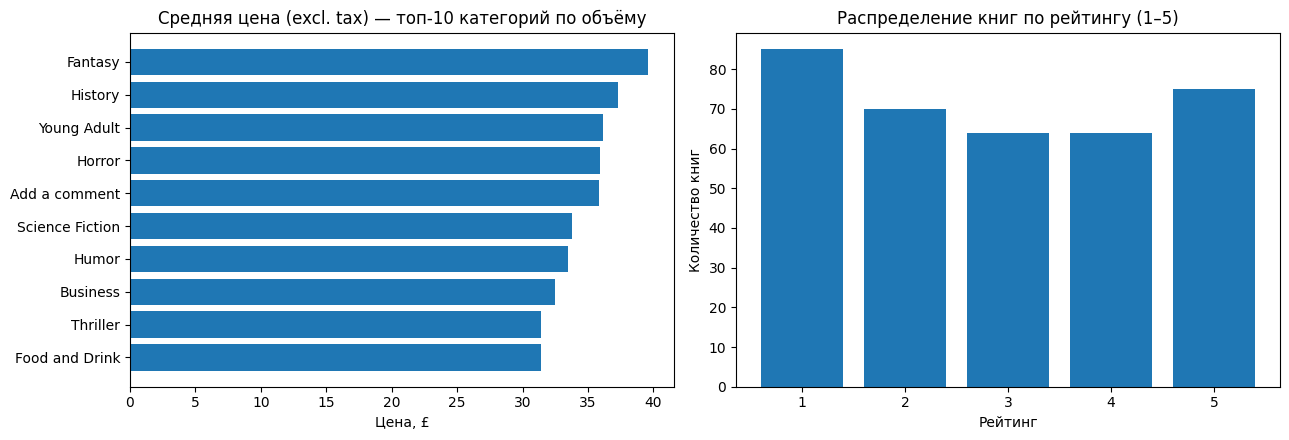

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

top10 = cat_agg.head(10).sort_values('средняя_цена')
axes[0].barh(top10['category_from_menu'], top10['средняя_цена'])
axes[0].set_title('Средняя цена (excl. tax) — топ-10 категорий по объёму')
axes[0].set_xlabel('Цена, £')

axes[1].bar(rating_agg['rating'].astype(str), rating_agg['книг'])
axes[1].set_title('Распределение книг по рейтингу (1–5)')
axes[1].set_xlabel('Рейтинг')
axes[1].set_ylabel('Количество книг')

plt.tight_layout()
plt.show()